<p style="text-align: right; margin: 0; line-height: 0;"><img width="100px" height="auto" src="../../.admin/img/eth_logo.png"></p>

<h1 style="text-align: center;">01 Data and Signals</h1>
<hr>


## **7. Correlation**

<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693

</div>


### 7.1 Introduction

The previous notebook, [Redundancy](01.6_Redundancy.ipynb), distinguished unequal symbol probabilities from predictable relationships between symbols. Symbol entropy $H(X_n)$ measures uncertainty about one symbol considered alone. Conditional entropy $H(X_n\mid X_{n-1})$ measures the uncertainty that remains when the previous symbol is known.

For example, a source that alternates `000 111 000 111 ...` and a source that independently chooses those symbols with equal probability both have symbol entropy one bit per source symbol. Only the alternating source is completely predictable from its previous symbol. Here we ask how relationships between numerical sample values can be detected, and how a receiver can locate a known pattern in a signal.

**Correlation measures particular relationships between values.** For sampled signals, we can use the numerical quantization-level indices represented by the three-bit words: `000` corresponds to 0 and `111` to 7. Correlation measures linear relationships between these values. Other forms of correlation compare shifted signals or look for repeating structure. Correlation can reveal some forms of redundancy, but it does not directly measure entropy or detect every kind of dependence.


### 7.2 Correlation Between Two Variables

Let $X$ and $Y$ represent paired numerical values. They could be measurements from two sensors, or the previous and current sample from one sensor. For the three-bit source, we interpret `000` and `111` as quantization-level indices 0 and 7.

The **correlation coefficient** measures the strength and direction of a *linear* relationship between two variables $X$ and $Y$:

$$\rho_{X,Y}=\frac{\operatorname{cov}(X,Y)}{\sigma_X\sigma_Y}.$$


This formula uses covariance and standard deviation. Covariance depends on the units and scale of the variables. Dividing it by $\sigma_X\sigma_Y$ normalizes it. The resulting correlation coefficient $\rho_{X,Y}$ has no unit and is limited to values between $-1$ and $+1$:

- $\rho_{X,Y}$ close to $+1$: larger values of $X$ tend to occur with larger values of $Y$.
- $\rho_{X,Y}$ close to $-1$: larger values of $X$ tend to occur with smaller values of $Y$.
- $\rho_{X,Y}$ close to $0$: there is little or no **linear** relationship.

The coefficient is defined only when both standard deviations are nonzero. A constant sequence has no variation, so its correlation is undefined.

Correlation measures only **linear** relationships. Therefore, a correlation coefficient near zero means only that there is little or no linear relationship; the variables may still have a strong nonlinear relationship and may still be dependent. For example, if $Y=X^2$, $X$ is symmetric around zero, and both variables have nonzero variance, knowing $X$ determines $Y$ exactly even though $\rho_{X,Y}=0$. Independence implies zero correlation when the correlation is defined, but zero correlation does not imply independence. Correlation is one way to find structure, not a detector of every kind of dependence or redundancy.

#### 7.2.1 Covariance $\operatorname{cov}(X,Y)$

$\operatorname{cov}(X,Y)$ is the **covariance** of $X$ and $Y$. It indicates whether the variables tend to deviate from their averages in the same direction. A positive covariance means that values above the average of $X$ tend to occur with values above the average of $Y$. A negative covariance means that values above the average of one variable tend to occur with values below the average of the other.

> For $N$ paired observations $(x_i,y_i)$, first calculate the averages
> 
> $$\bar{x}=\frac{1}{N}\sum_{i=1}^{N}x_i, \qquad \bar{y}=\frac{1}{N}\sum_{i=1}^{N}y_i.$$
> 
> Then calculate the covariance by multiplying the paired deviations and taking their average:
>
> $$\operatorname{cov}(X,Y)=\frac{1}{N}\sum_{i=1}^{N}(x_i-\bar{x})(y_i-\bar{y}).$$

Here we treat the observed pairs as an empirical distribution, using $1/N$ for both covariance and variance. Some statistical estimators use $1/(N-1)$ instead; using the same convention in both places gives the same correlation coefficient.



#### 7.2.2 Standard Deviation $\sigma$
$\sigma_X$ and $\sigma_Y$ are the **standard deviations** of $X$ and $Y$. A standard deviation describes how widely the values of a variable are spread around their average. A small standard deviation means that the values stay close to the average; a large standard deviation means that they vary more widely. The standard deviations are calculated from the squared deviations of each variable from its own average:

$$\sigma_X=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(x_i-\bar{x})^2}, \qquad \sigma_Y=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\bar{y})^2}.$$


#### 7.2.3 Calculation Example

Let $X=[1,2,3]$ and $Y=[5,7,9]$. There are $N=3$ paired observations, so we divide by three when calculating the averages, covariance, and variances. Their averages are $\bar{x}=2$ and $\bar{y}=7$. The deviations are $[-1,0,1]$ and $[-2,0,2]$. Therefore,

$$\operatorname{cov}(X,Y)=\frac{(-1)(-2)+(0)(0)+(1)(2)}{3}=\frac{4}{3},$$

$$\sigma_X=\sqrt{\frac{1+0+1}{3}}=\sqrt{\frac{2}{3}}, \qquad \sigma_Y=\sqrt{\frac{4+0+4}{3}}=\sqrt{\frac{8}{3}}.$$

Substituting these values gives $\rho_{X,Y}=1$, indicating a perfect positive linear relationship.




#### 7.2.4 Graphical Examples



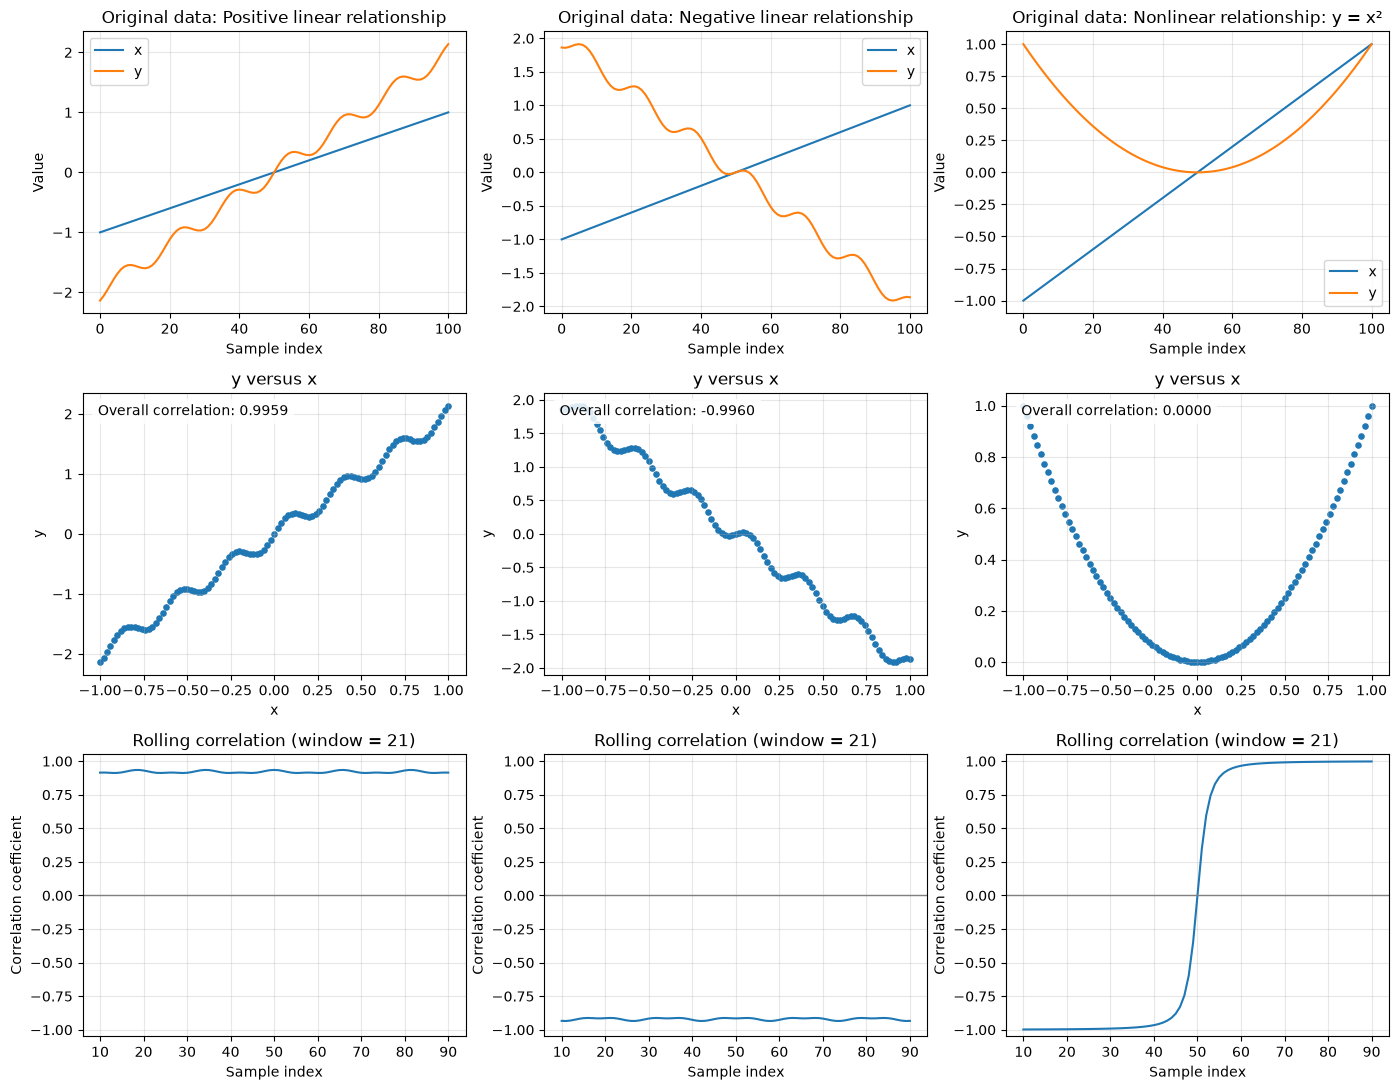

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 101)
examples = {
    "Positive linear relationship": 2*x + 0.15*np.sin(20*x),
    "Negative linear relationship": -2*x + 0.15*np.sin(20*x),
    "Nonlinear relationship: y = x²": x**2,
}

sample_index = np.arange(len(x))
window_size = 21
half_window = window_size // 2
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for column, (title, y) in enumerate(examples.items()):
    rho = np.corrcoef(x, y)[0, 1]

    axes[0, column].plot(sample_index, x, label="x")
    axes[0, column].plot(sample_index, y, label="y")
    axes[0, column].set_title(f"Original data: {title}")
    axes[0, column].set_xlabel("Sample index")
    axes[0, column].set_ylabel("Value")
    axes[0, column].legend()
    axes[0, column].grid(True, alpha=0.3)

    axes[1, column].scatter(x, y, s=14)
    axes[1, column].set_title("y versus x")
    axes[1, column].text(
        0.04, 0.96, f"Overall correlation: {rho:.4f}",
        transform=axes[1, column].transAxes, ha="left", va="top",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85),
    )
    axes[1, column].set_xlabel("x")
    axes[1, column].set_ylabel("y")
    axes[1, column].grid(True, alpha=0.3)

    rolling_correlation = np.full(len(x), np.nan)
    for center in range(half_window, len(x) - half_window):
        start = center - half_window
        stop = center + half_window + 1
        rolling_correlation[center] = np.corrcoef(x[start:stop], y[start:stop])[0, 1]

    axes[2, column].plot(sample_index, rolling_correlation)
    axes[2, column].axhline(0, color="gray", linewidth=1)
    axes[2, column].set_title(f"Rolling correlation (window = {window_size})")
    axes[2, column].set_xlabel("Sample index")
    axes[2, column].set_ylabel("Correlation coefficient")
    axes[2, column].set_ylim(-1.05, 1.05)
    axes[2, column].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


The top row shows $x$ and $y$ against sample index. The middle row plots $y$ against $x$; the label inside each plot gives their overall correlation coefficient, a single number calculated from all paired values. The scatter points themselves are not correlation values.

In the third plot, $Y=X^2$, so knowing $X$ determines $Y$ exactly. Nevertheless, correlation is approximately zero because the relationship is not linear. Therefore, **uncorrelated does not mean unpredictable**.

The bottom row shows a **rolling correlation**. At each position, the correlation coefficient is calculated from a local window of 21 paired observations. This shows how the linear relationship can change along the observation sequence.

Rolling correlation turns one overall coefficient into a sequence of local coefficients along the sample index. We can extend correlation in another direction: instead of moving a window through paired samples, we can shift one complete signal relative to another and calculate similarity at each **lag**. This produces the cross-correlation introduced next. Rolling correlation and cross-correlation are related ideas, but they answer different questions: rolling correlation asks how a relationship changes with position, while cross-correlation asks at which shift two signals align.


### 7.3 Correlation Across Time: Cross-Correlation

So far, we have compared values at matching sample positions to look for a relationship. A receiver has another practical task: locating a known pattern, such as a packet preamble, when its arrival time is unknown. We therefore compare the pattern at several shifts, called **lags**. One lag step corresponds to one sampling interval. **Cross-correlation** compares one signal with shifted versions of another. For finite real-valued signals, we use

$$R_{x,y}[k]=\sum_{n=0}^{N_x-1}x[n]y[n-k],$$

where values of $y$ outside its valid index range are treated as zero. The lag $k$ runs from $-N_y+1$ to $N_x-1$. At each lag, shift $y$, multiply overlapping samples, and add the products. A large positive value indicates alignment with the same polarity; a large negative value can indicate alignment with reversed polarity. The magnitude also depends on sample amplitudes and the amount of overlap.

For $x=[1,2,3]$ and $y=[1,2]$, the full result is $[2,5,8,3]$. For example, $R_{x,y}[1]=2\cdot1+3\cdot2=8$. A receiver can use a correlation peak to find a known preamble in noise or estimate a signal delay.

> Raw cross-correlation is not the normalized correlation coefficient and is not restricted to $[-1,1]$. It sums products without subtracting means or dividing by standard deviations. It has the units of the product of the two signal values. In our convention, positive $k$ shifts the pattern $y$ to the right relative to $x$.

The plots below apply this operation to the same numerical examples as before. Comparing their cross-correlation curves with their correlation coefficients shows that these measures answer different questions.


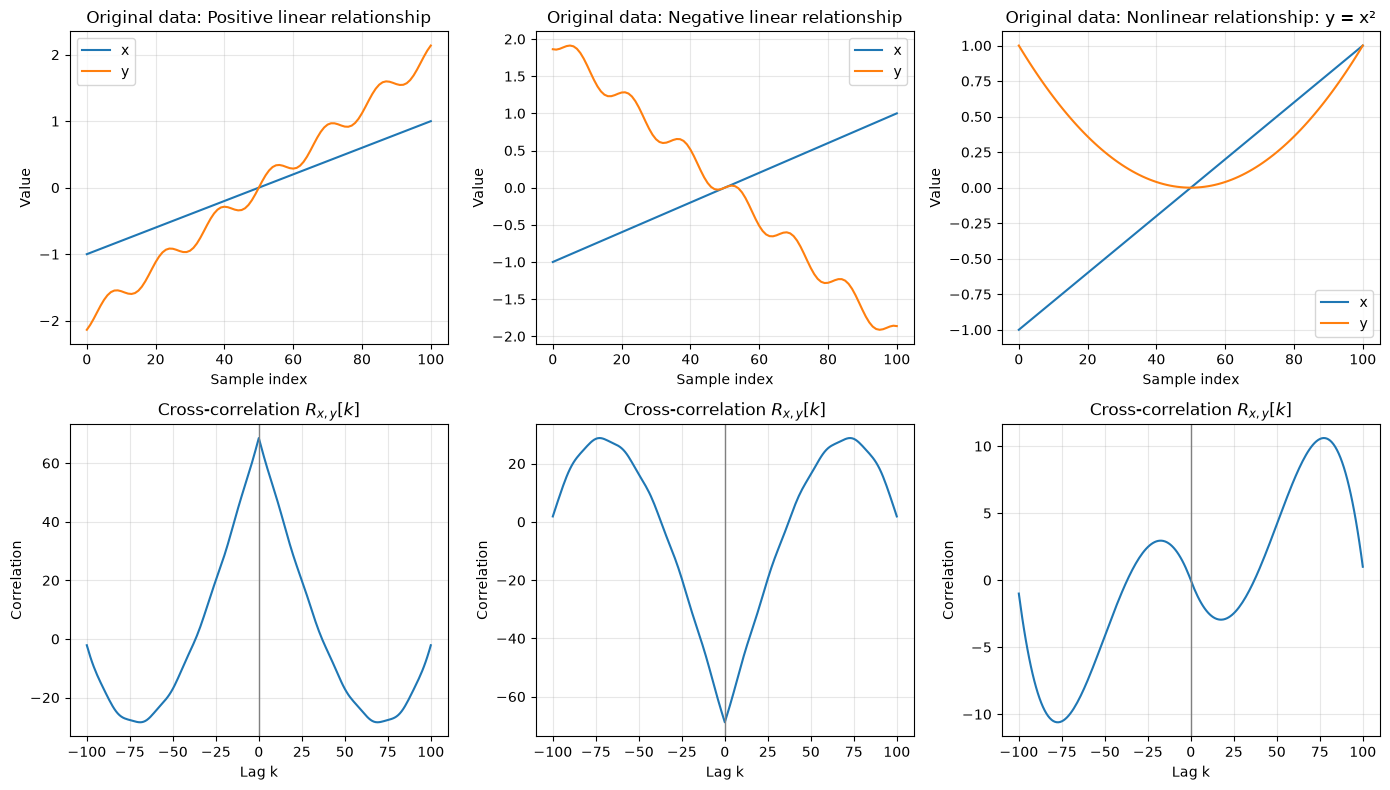

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 101)
examples = {
    "Positive linear relationship": 2*x + 0.15*np.sin(20*x),
    "Negative linear relationship": -2*x + 0.15*np.sin(20*x),
    "Nonlinear relationship: y = x²": x**2,
}

sample_index = np.arange(len(x))
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for column, (title, y) in enumerate(examples.items()):
    lags = np.arange(-len(y) + 1, len(x))
    correlation = np.correlate(x, y, mode="full")

    axes[0, column].plot(sample_index, x, label="x")
    axes[0, column].plot(sample_index, y, label="y")
    axes[0, column].set_title(f"Original data: {title}")
    axes[0, column].set_xlabel("Sample index")
    axes[0, column].set_ylabel("Value")
    axes[0, column].legend()
    axes[0, column].grid(True, alpha=0.3)

    axes[1, column].plot(lags, correlation)
    axes[1, column].axvline(0, color="gray", linewidth=1)
    axes[1, column].set_title("Cross-correlation $R_{x,y}[k]$")
    axes[1, column].set_xlabel("Lag k")
    axes[1, column].set_ylabel("Correlation")
    axes[1, column].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 7.4 Autocorrelation: Predictability Within One Signal

**Autocorrelation** is cross-correlation of a signal with a shifted copy of itself:

$$R_{x,x}[k]=\sum_n x[n]x[n-k].$$

It asks: *Does the signal resemble its recent past?*

A slowly changing signal tends to have high autocorrelation at small lags because nearby samples are similar. A periodic signal produces repeated peaks at lags that match its period. Independent, zero-mean noise has zero expected autocorrelation at nonzero lags, although a finite sample produces fluctuations. For real-valued signals, autocorrelation is symmetric, which means $R_{x,x}[k]=R_{x,x}[-k]$.

At lag zero, $R_{x,x}[0]=\sum_n x[n]^2$, the discrete-time signal energy. Dividing it by the number of samples gives the mean-square value.

The plots below subtract each signal's sample mean before calculating autocorrelation, so they show relationships between deviations from that mean. This removes the constant offset that would otherwise contribute at many lags. For the alternating levels `0 7 0 7 ...`, the centered values alternate between $-3.5$ and $+3.5$: their autocorrelation changes sign at successive lags and repeats every two lags. This reveals the same predictable structure discussed in the redundancy notebook.


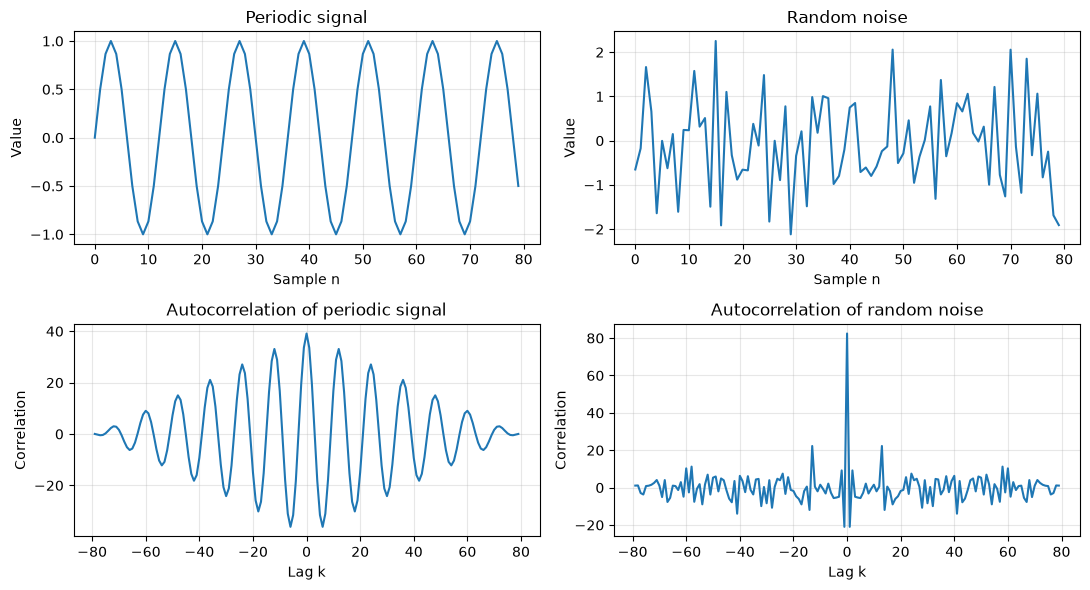

In [3]:
rng = np.random.default_rng(4)
n = np.arange(80)
signals = {
    "Periodic signal": np.sin(2*np.pi*n/12),
    "Random noise": rng.normal(size=len(n)),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for column, (name, signal) in enumerate(signals.items()):
    centered = signal - signal.mean()
    autocorr = np.correlate(centered, centered, mode="full")
    lags = np.arange(-len(signal)+1, len(signal))
    axes[0, column].plot(n, signal)
    axes[0, column].set_title(name)
    axes[0, column].set_xlabel("Sample n")
    axes[0, column].set_ylabel("Value")
    axes[1, column].plot(lags, autocorr)
    axes[1, column].set_title(f"Autocorrelation of {name.lower()}")
    axes[1, column].set_xlabel("Lag k")
    axes[1, column].set_ylabel("Correlation")
    axes[0, column].grid(True, alpha=0.3)
    axes[1, column].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 7.4.1 Correlation of the Sequences from the Entropy Notebook

The table displays the same **16 three-bit symbols** per row as Section 5.3.1 of the [Entropy notebook](01.5_Entropy.ipynb). For clearer correlation graphs, we extend each example to **4,096 symbols** and show lags 0 through 32. Each three-bit word is interpreted as a numerical level from 0 to 7.

The constant and ordered examples repeat their displayed 16-symbol block. In particular, the third row now repeats eight `000` symbols followed by eight `111` symbols, giving a period of 16. For the two shuffled examples, we keep the displayed symbols at the start and generate the remaining symbols independently, using the symbol probabilities from that row. We do not repeat the shuffled blocks, since that would introduce an artificial period of 16.

The entropy column still describes the **displayed 16-symbol example**. The graphs use the extended sequences. These extensions are explicit source models for illustration; a short observed sequence alone does not establish how its source will continue.

Here we plot a **correlation coefficient at each lag**, rather than the unnormalized autocorrelation sum used above. With $N=4096$, we calculate

$$
r[k]=\operatorname{corr}\bigl((x[0],\ldots,x[N-1-k]),\ (x[k],\ldots,x[N-1])\bigr),
\qquad k=0,\ldots,32.
$$

Each pair of overlapping lists is centered and normalized using its own mean and standard deviation. Defined values lie between $-1$ and $1$. Lag zero compares the sequence with itself. This differs from rolling correlation: we vary the **separation between paired samples**, rather than moving a fixed-size window along them.

| Example and sequence (read left to right, then continue on the next line) | Entropy of displayed example [bit per source symbol] | Correlation over 4,096 symbols |
|:---|---:|:---|
| Only `000`<br>`... 000 000 000 000 000 000 000 000`<br>`000 000 000 000 000 000 000 000 ...` | 0.000 | <img src="../../.admin/notebooks/picture/correlation_sequence_01.svg" alt="Lagged correlation graph for Only '000'" width="440" style="max-width:100%;height:auto;"> |
| Only `111`<br>`... 111 111 111 111 111 111 111 111`<br>`111 111 111 111 111 111 111 111 ...` | 0.000 | <img src="../../.admin/notebooks/picture/correlation_sequence_02.svg" alt="Lagged correlation graph for Only '111'" width="440" style="max-width:100%;height:auto;"> |
| Eight `000`, then eight `111`<br>`... 000 000 000 000 000 000 000 000`<br>`111 111 111 111 111 111 111 111 ...` | 1.000 | <img src="../../.admin/notebooks/picture/correlation_sequence_03.svg" alt="Lagged correlation graph for Eight '000', then eight '111'" width="440" style="max-width:100%;height:auto;"> |
| Alternating `000` and `111`<br>`... 000 111 000 111 000 111 000 111`<br>`000 111 000 111 000 111 000 111 ...` | 1.000 | <img src="../../.admin/notebooks/picture/correlation_sequence_04.svg" alt="Lagged correlation graph for Alternating '000' and '111'" width="440" style="max-width:100%;height:auto;"> |
| All eight symbols, repeated in order<br>`... 000 001 010 011 100 101 110 111`<br>`000 001 010 011 100 101 110 111 ...` | 3.000 | <img src="../../.admin/notebooks/picture/correlation_sequence_05.svg" alt="Lagged correlation graph for All eight symbols, repeated in order" width="440" style="max-width:100%;height:auto;"> |
| All eight symbols, randomly shuffled<br>`... 010 000 100 001 010 101 001 111`<br>`000 101 011 110 100 110 111 011 ...` | 3.000 | <img src="../../.admin/notebooks/picture/correlation_sequence_06.svg" alt="Lagged correlation graph for All eight symbols, randomly shuffled" width="440" style="max-width:100%;height:auto;"> |
| Unequal symbol frequencies, shuffled<br>`... 010 000 000 001 001 000 000 100`<br>`010 001 000 001 000 011 000 000 ...` | 1.875 | <img src="../../.admin/notebooks/picture/correlation_sequence_07.svg" alt="Lagged correlation graph for Unequal symbol frequencies, shuffled" width="440" style="max-width:100%;height:auto;"> |

The constant sequences have zero entropy, but their correlation coefficients are **undefined**, because their standard deviations are zero. Undefined does not mean zero correlation or an absence of predictability.

The alternating sequence has correlation $-1$ at odd lags and $+1$ at even lags. The repeated eight-symbol ordered block has correlation $+1$ at lags 8, 16, 24, and 32. The repeated block of eight `000` symbols followed by eight `111` symbols has correlation $-1$ at lag 8 and $+1$ at lag 16. These patterns show how lagged correlation can reveal repetition that symbol entropy does not describe.

For the independently extended shuffled examples, the correlations at nonzero lags fluctuate around zero. The longer records reduce the chance fluctuations seen with only 16 symbols, but the estimates are still not exact source properties. Entropy uses symbol probabilities, whereas correlation also depends on the order and numerical levels of the symbols.


### 7.5 Comparing Correlation, Entropy, and Mutual Information

Return to the three sources from Section 6.3.3 of the redundancy notebook. Use the same names throughout: **Source A is independent**, **Source B alternates**, and **Source C is biased and dependent**. Each uses the three-bit symbols `000` and `111`, interpreted here as numerical levels 0 and 7.

The table gives theoretical values under the source models, not estimates from a finite sequence. Entropy and conditional entropy are in **bits per source symbol**, mutual information is in **bits per adjacent symbol pair**, and correlation is **dimensionless**.

| Source | $H(X_n)$ | $H(X_n\mid X_{n-1})$ | $I(X_n;X_{n-1})$ | $\rho_{X_n,X_{n-1}}$ |
|:---|---:|---:|---:|---:|
| A: independent, equally likely symbols | $1$ | $1$ | $0$ | $0$ |
| B: alternating, either starting symbol equally likely | $1$ | $0$ | $1$ | $-1$ |
| C: biased and dependent | $\approx0.811$ | $\approx0.572$ | $\approx0.239$ | $0.6$ |

**Negative correlation can mean complete predictability.** For Source B, the next numerical level is $X_n=7-X_{n-1}$. When one value is high, the next is low, giving a perfect negative linear relationship. Yet the previous symbol determines the next exactly, so mutual information is one bit. Correlation describes the direction of a linear relationship; mutual information measures the reduction in uncertainty and cannot be negative.

**Partial predictability gives intermediate values.** Source C uses $P(\texttt{111}\mid\texttt{000})=0.1$ and $P(\texttt{111}\mid\texttt{111})=0.7$, with stationary probabilities $P(\texttt{000})=0.75$ and $P(\texttt{111})=0.25$. Given the previous numerical level $x$, its expected next level is

$$
\mathbb{E}[X_n\mid X_{n-1}=x]=0.7+0.6x,\qquad x\in\{0,7\}.
$$

The symbol distributions, and therefore their variances, are the same at successive positions. The conditional mean has slope $0.6$, giving $\operatorname{cov}(X_n,X_{n-1})=0.6\operatorname{var}(X_{n-1})$ and hence $\rho=0.6$. This is a property of this particular source model, not a general conversion between correlation and mutual information.

**Zero correlation is not a general test for independence.** The nonlinear example $Y=X^2$ already showed why. Also, even independence of adjacent symbols does not establish independence of the entire sequence. The repeating pattern `000 000 111 111 ...`, with a uniformly random starting position, has zero adjacent correlation and zero adjacent mutual information. Two previous symbols nevertheless determine the next one. Looking at additional lags or longer contexts can reveal structure that an adjacent-pair comparison misses.


Entropy and mutual information quantify uncertainty through probabilities. Correlation describes particular relationships between numerical values. Correlation measures linear dependence, cross-correlation compares shifted signals, and autocorrelation can reveal repeated structure within one signal. These tools can help identify redundancy, but a correlation coefficient alone does not determine how many bits compression can save. The later Source Coding notebook explores how a model and a decodable code turn predictable structure into shorter representations.


---

### 7.6 Hands-On Exercise

<div class="alert alert-block alert-info">Fill in your responses and save this notebook. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>


**Source A independently chooses `000` or `111` with equal probability. Source B alternates `000 111 000 111 ...`, with either starting symbol equally likely. Interpret the symbols as numerical levels 0 and 7. Determine the correlation coefficient and mutual information between adjacent symbols for each source. Explain why perfect negative correlation can still mean complete predictability.**

Source A picks `000` (level 0) or `111` (level 7) independently with equal probability. Because each symbol is independent of the previous one, the covariance between adjacent levels is zero, so $\rho = 0$. Knowing the previous symbol does not reduce the uncertainty about the next one: $H(X_n)=1$ bit and $H(X_n\mid X_{n-1})=1$ bit, so the mutual information is $I(X_n;X_{n-1})=1-1=0$ bits.

Source B alternates, so the next level is always $X_n = 7-X_{n-1}$. This is an exact linear relationship with a negative slope, so $\rho=-1$. The previous symbol determines the next one completely: $H(X_n)=1$ bit, but $H(X_n\mid X_{n-1})=0$, so $I(X_n;X_{n-1})=1-0=1$ bit.

Perfect negative correlation can still mean complete predictability because the sign of $\rho$ only indicates the direction of the linear relationship; it does not indicate how predictable the next value is. Here, $\rho=-1$ means that a high value is always followed by a low value, and vice versa. This relationship is just as deterministic as $\rho=+1$. The strength of the linear relationship is reflected by $|\rho|=1$. Mutual information measures the reduction in uncertainty and cannot be negative. Here it reaches its maximum of 1 bit.


**In Section 7.2.4, explain the difference between the middle-row scatter plots, their overall-correlation labels, and the bottom-row rolling correlation. Use the example $Y=X^2$ to explain why an overall correlation near zero does not necessarily mean that $Y$ is unpredictable from $X$.**

The middle-row scatter plots show the raw data: each point is one paired observation $(x_i, y_i)$. The points themselves are not correlation values. The label inside each scatter plot is a single number, the overall correlation coefficient, computed from all 101 pairs at once. It summarizes how well the entire cloud of points fits a straight line. The bottom-row rolling correlation computes a separate correlation coefficient for each local window of 21 consecutive pairs. The result is a sequence of local coefficients along the sample index, showing how the linear relationship changes from one part of the data to another.

For $Y = X^2$, the scatter plot is a parabola, and the overall correlation is about $0$. Over the left half ($x < 0$), $Y$ decreases as $X$ increases, which is a negative trend. Over the right half, $Y$ increases, which is a positive trend. These cancel in the overall coefficient. The rolling correlation makes this visible: it is strongly negative for early samples, passes through zero near the middle, and becomes strongly positive for later samples. Yet $Y$ is completely determined by $X$: knowing $X$ gives $Y = X^2$ exactly. The overall correlation is near zero only because the relationship is not linear, so uncorrelated does not mean unpredictable.

**Use the autocorrelation plot in Section 7.4 to estimate the periodic signal's period in samples. Explain which peaks support your estimate and why the peak at lag zero alone does not establish periodicity.**

The period is about 12 samples, which matches the code's `np.sin(2*np.pi*n/12)`. Besides the main peak at lag $0$, the autocorrelation shows repeated positive peaks at lags $\pm12$, $\pm24$, $\pm36$, and so on. The spacing between successive peaks is 12 lags. Negative troughs also appear halfway between the peaks, at $\pm6$, $\pm18$, and so on, where the shifted signal is in opposite phase. The peak heights shrink as $|k|$ grows because fewer samples overlap at larger shifts, not because the periodicity weakens.

The peak at lag $0$ alone proves nothing about periodicity. Every signal has its maximum autocorrelation at lag zero, because $R_{X,X}[0] = \sum x[n]^2$ is just the signal energy, a signal compared with itself unshifted. The random-noise plot also has a large lag-$0$ peak, but no repeated peaks elsewhere. Periodicity is shown only by the additional peaks at nonzero lags that recur at regular spacing.

**Complete and check the cross-correlation function below.**

1. Find the line `for k in range(0,0):` marked `MODIFY HERE`. Replace the two zeros with expressions that make `k` take every integer value from `k_min` to `k_max`, including both endpoints. The rest of the function is already complete.
2. Run the cell. It compares your function with NumPy for `x_test = [1, 2, 3]` and `y_test = [1, 2]`. If the check fails, review the values used in `range(...)`.
3. To check your handwritten table, change the two test lists to `x_test = [2, 1, -1, -2]` and `y_test = [1, 2]`. Add `print(result)` at the end of the cell and run it again. The five printed values correspond to lags `-1, 0, 1, 2, 3`, in that order. Compare them with your table.

Hint: Python includes the first value of `range(start, stop)` but excludes `stop`.

In [5]:
import numpy as np

def my_correlation(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    k_min = -len(y) + 1
    k_max = len(x) - 1
    result = []

    for k in range(k_min, k_max + 1):  # MODIFY HERE
        value = 0.0
        for n in range(len(x)):
            m = n - k
            if 0 <= m < len(y):
                value += x[n] * y[m]
        result.append(value)

    return np.array(result)

x_test = [1, 2, 3]
y_test = [1, 2]
try:
    result = my_correlation(x_test, y_test)
    expected = np.correlate(x_test, y_test, mode="full")
    if np.array_equal(result, expected):
        print("Correlation matches NumPy's result.")
    else:
        print("Not correct yet. Check that your range includes every lag from k_min through k_max.")
except Exception:
    print("The function could not run. Replace both values in range(...) with valid integer expressions.")


Correlation matches NumPy's result.


The `+ 1` is needed because `range` excludes its stop value, and `k_max` itself must be included. With `x_test = [1, 2, 3]` and `y_test = [1, 2]`, the cell prints "Correlation matches NumPy's result." and gives `[2, 5, 8, 3]`.

For step 3, set `x_test = [2, 1, -1, -2]` and `y_test = [1, 2]`, then add `print(result)`. The output should be:

$[ 4.  4. -1. -5. -2.]$

Worked out by hand for lags $-1$ to $3$:
| Lag $k$ | Products                  | $R[k]$ |
| ------- | ------------------------- | ------ |
| $-1$    | $2\cdot2$                 | $4$    |
| $0$     | $2\cdot1 + 1\cdot2$       | $4$    |
| $1$     | $1\cdot1 + (-1)\cdot2$    | $-1$   |
| $2$     | $(-1)\cdot1 + (-2)\cdot2$ | $-5$   |
| $3$     | $(-2)\cdot1$              | $-2$   |

The largest magnitude is at lag $2$, where the pattern [1, 2] overlaps [-1, -2]. That is the same shape with reversed polarity, so the value is strongly negative.

**OPTIONAL: Did you understand all tasks? Which explanation or exercise should be improved?**  

(please help the team by telling us what part was not understood, and we will work on it)
